In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Telco Customer Churn.csv")
df.head(7)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

! Replacing the blankspaces in TotalCharges with zero because Tenure is 0 as well

In [4]:
df["TotalCharges"] = df["TotalCharges"].replace(" ",0)
df["TotalCharges"] = df["TotalCharges"].astype("float")

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

! Checking for nulls

In [6]:
df.isnull().sum().sum() #using .sum() 2 times to get the result of nulls

np.int64(0)

In [7]:
#checking some major things in data by using .describe()
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [82]:
#Checking duplicates
df.duplicated().sum()

np.int64(0)

! Converting 0 and 1 value of SeniorCitizen to yes/no to make it easier to understand.
For this I created a function 

In [8]:
def con(value):
    if value == 1:
        return "Yes"
    else:
        return "No"
df["SeniorCitizen"] = df["SeniorCitizen"].apply(con)

! Starting analysis

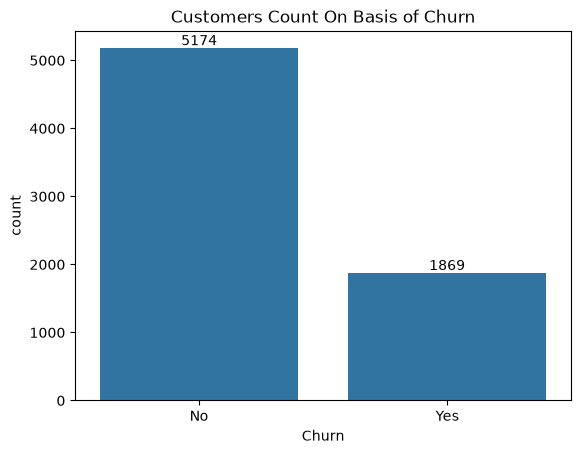

In [56]:
bl = sns.countplot(data = df , x = "Churn")
plt.title("Customers Count On Basis of Churn")
bl.bar_label(bl.containers[0])
plt.show()

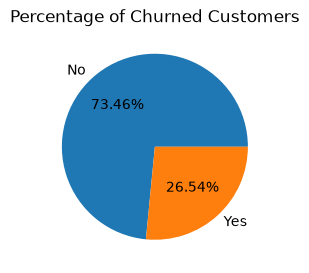

In [92]:
gp = df.groupby("Churn").agg({"Churn":"count"})
plt.figure(figsize= (3,4))
plt.title("Percentage of Churned Customers")
plt.pie(gp["Churn"],labels = gp.index, autopct = "%1.2f%%")
plt.show()

! From the pie chart we got that 26.54% of people have churned. 
Doing more analysis to know why they left

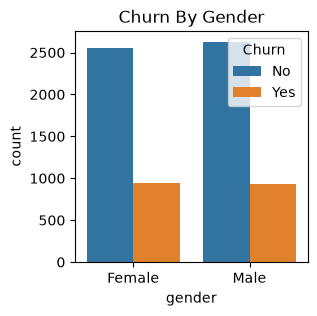

In [55]:
plt.figure(figsize= (3,3))
sns.countplot(data = df,x = "gender",hue = "Churn")
plt.title("Churn By Gender")
plt.show()
#here we can see almost males and females are equally churning out 

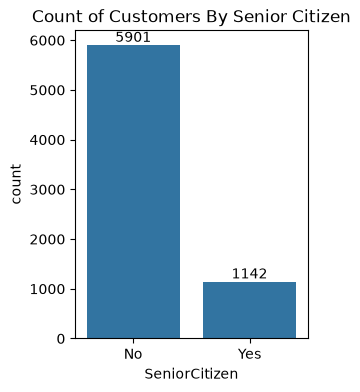

In [60]:
plt.figure(figsize= (3,4))
bl = sns.countplot(data = df,x = "SeniorCitizen")
bl.bar_label(bl.containers[0])
plt.title("Count of Customers By Senior Citizen")
plt.show()

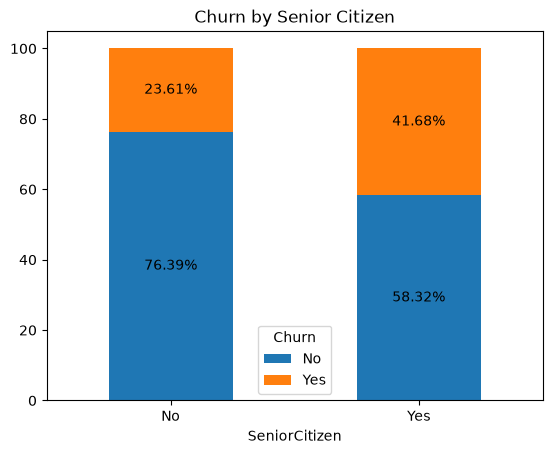

In [48]:
ax = pd.crosstab(df["SeniorCitizen"], df["Churn"], normalize="index").mul(100).plot(kind="bar", stacked=True)

for c in ax.containers:
    ax.bar_label(c, fmt="%1.2f%%", label_type="center")

plt.title("Churn by Senior Citizen")
plt.xticks(rotation=0)
plt.show()

! From the upper analysis we got that the people who churned most are senior citizen

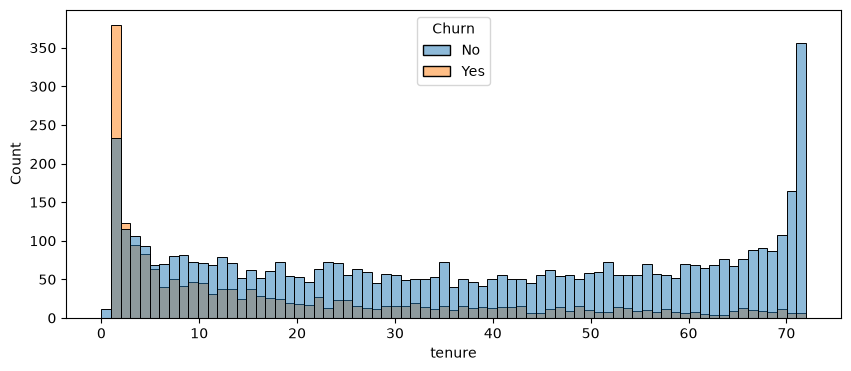

In [65]:
plt.figure(figsize = (10,4))
sns.histplot(data = df,x = "tenure",hue = "Churn",bins= 73)
plt.show()

! People who used our services for a long time stayed with us 
meanwhile people who used our services for 1 or 2 month have chunred

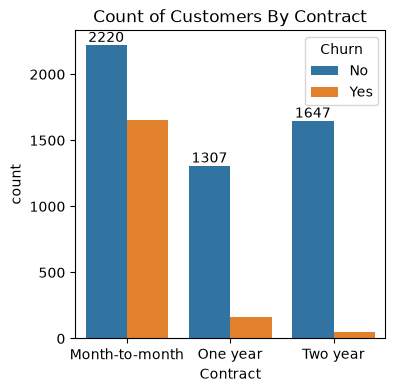

In [78]:
plt.figure(figsize= (4,4))
bl = sns.countplot(data = df,x = "Contract",hue = "Churn")
bl.bar_label(bl.containers[0])
plt.title("Count of Customers By Contract")
plt.show()

! People who have month-to-month contract are likely to churn
people who have 1 year and 2 year contract are staying they churn less

In [73]:
df.columns.values

<StringArray>
[      'customerID',           'gender',    'SeniorCitizen',
          'Partner',       'Dependents',           'tenure',
     'PhoneService',    'MultipleLines',  'InternetService',
   'OnlineSecurity',     'OnlineBackup', 'DeviceProtection',
      'TechSupport',      'StreamingTV',  'StreamingMovies',
         'Contract', 'PaperlessBilling',    'PaymentMethod',
   'MonthlyCharges',     'TotalCharges',            'Churn']
Length: 21, dtype: str

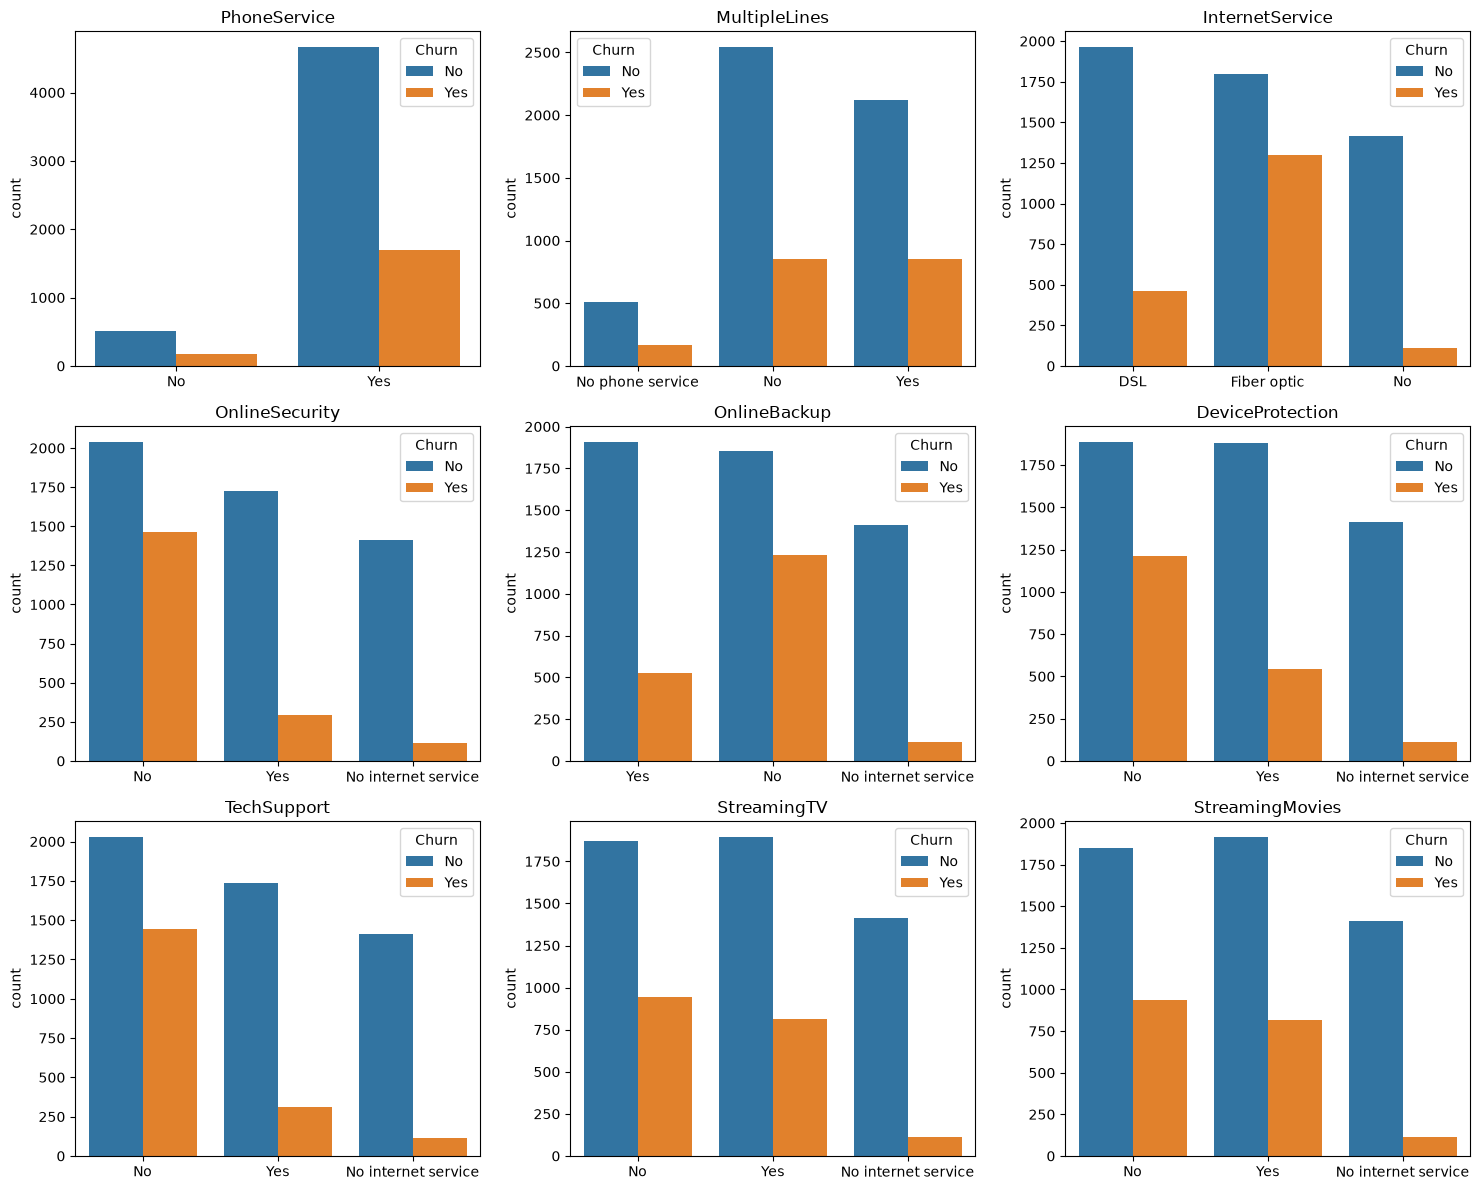

In [83]:
cols = ['PhoneService', 'MultipleLines', 'InternetService',
        'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
        'TechSupport', 'StreamingTV', 'StreamingMovies']

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for ax, col in zip(axes, cols):
    sns.countplot(data=df, x=col, ax=ax,hue = "Churn")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

#Customers with Fiber optic internet churn the most, with a large share of them leaving, 
while DSL customers churn far less and customers with no internet service almost never churn. 
Customers who lack add-on services like OnlineSecurity, OnlineBackup, DeviceProtection and 
TechSupport churn noticeably more than those who have them, whereas StreamingTV, StreamingMovies and 
MultipleLines show little difference between Yes and No.

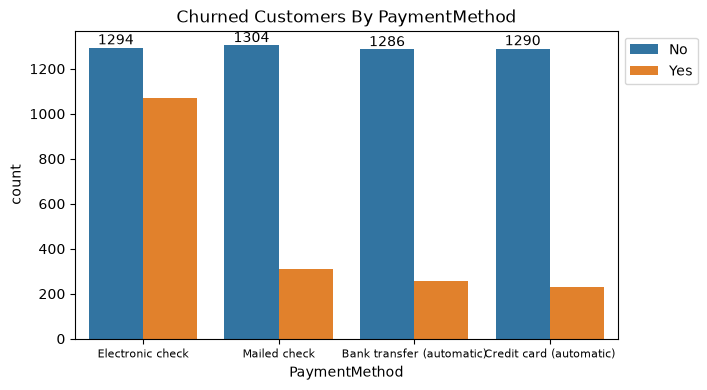

In [89]:
plt.figure(figsize= (7,4))
bl = sns.countplot(data = df,x = "PaymentMethod",hue = "Churn")
bl.bar_label(bl.containers[0])
plt.title("Churned Customers By PaymentMethod")
bl.tick_params(axis="x", labelsize=8)
plt.legend(bbox_to_anchor = (1,1))
plt.show()

! People having cards, banks and automatic transfer are not churnig

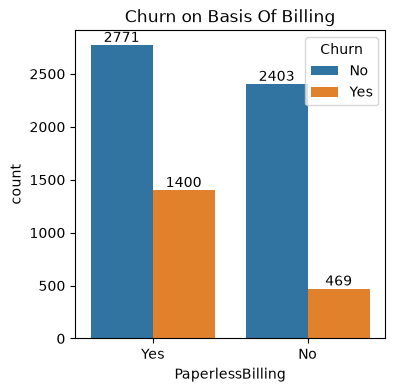

In [91]:
plt.figure(figsize= (4,4))
bl = sns.countplot(data = df,x = "PaperlessBilling",hue = "Churn")
bl.bar_label(bl.containers[0])
bl.bar_label(bl.containers[1])
plt.title("Churn on Basis Of Billing")
plt.show()

! Here we can see the PaperLess Billing is also effecting If we goes towards PaperBilling we will have more customers

In [94]:
df["TenureGroup"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                           labels=["0-12 m", "13-24 m", "25-48 m", "49-72 m"])
print((df.groupby("TenureGroup", observed=True)["ChurnFlag"].mean() * 100).round(2))

TenureGroup
0-12 m     47.44
13-24 m    28.71
25-48 m    20.39
49-72 m     9.51
Name: ChurnFlag, dtype: float64


! Churn drops sharply with tenure, from 47.44% in the first 12 months to 9.51% for customers with over 4 years. The first year is the highest-risk period

In [95]:
print("Monthly revenue lost to churn:", df[df["Churn"] == "Yes"]["MonthlyCharges"].sum().round(2))
print("\nAverage monthly charge by churn:")
print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

Monthly revenue lost to churn: 139130.85

Average monthly charge by churn:
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


! **Revenue impact:** Churned customers represent 139,130.85 USD in lost monthly recurring revenue (about 1.67M USD annualized). They also paid more on average (74.44 USD/month vs 61.27 USD), which suggests the business is losing higher-value customers.

In [96]:
risk = df[(df["Contract"] == "Month-to-month")
          & (df["InternetService"] == "Fiber optic")
          & (df["TechSupport"] == "No")
          & (df["tenure"] <= 12)]

print("Customers in this group:", len(risk))
print("Churn rate of this group:", round(risk["ChurnFlag"].mean() * 100, 2), "%")
print("Overall churn rate:", round(df["ChurnFlag"].mean() * 100, 2), "%")

Customers in this group: 833
Churn rate of this group: 71.07 %
Overall churn rate: 26.54 %


! **High-risk customer profile:** Customers who are on a month-to-month contract, use fiber optic internet, have no tech support, and have been with the company 12 months or less (833 customers, about 12% of the base) churn at **71.07%**, compared with an overall churn rate of **26.54%**. This is roughly 2.7 times the average, and it identifies the group where retention efforts would have the most impact.

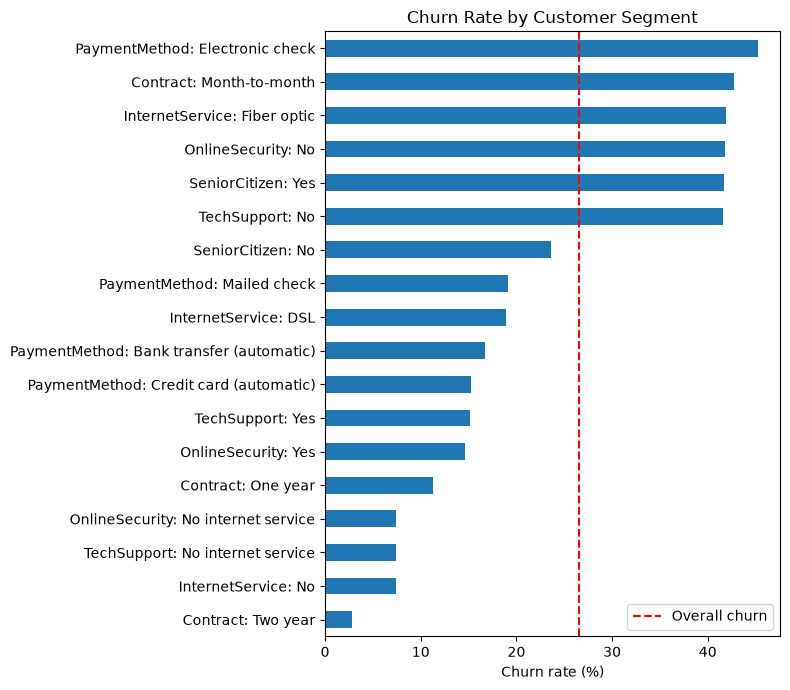

In [98]:
rates = {}
for col in ["Contract", "InternetService", "TechSupport", "OnlineSecurity", "SeniorCitizen", "PaymentMethod"]:
    for cat, val in (df.groupby(col)["ChurnFlag"].mean() * 100).items():
        rates[f"{col}: {cat}"] = val

s = pd.Series(rates).sort_values()
plt.figure(figsize=(8, 7))
s.plot(kind="barh")
plt.axvline(df["ChurnFlag"].mean() * 100, color="red", linestyle="--", label="Overall churn")
plt.xlabel("Churn rate (%)")
plt.title("Churn Rate by Customer Segment")
plt.legend()
plt.tight_layout()
plt.savefig("bn.jpg")
plt.show()

! *Note: "No internet service" segments reflect customers without internet at all, so they are not comparable to customers who chose not to buy an add-on.*